# Utilidade

O X6 treina o boosting e as duas logísticas com as internações de 2019 a 2023, calibra com as de 2024 e testa nas de
2025. Dele saem as frações liberadas por cada modelo e as diferenças que H4 usa; o notebook mostra também a calibração
do boosting no teste, a importância das variáveis e a comparação com uma banda de custo. Os números vêm
de `reports/exploratorios/morte/nenhuma/resultados_x6.json`, e as figuras, de `reports/figures/morte/`.

In [1]:
import json
from functools import partial

import pandas as pd
from IPython.display import Image

from triagem_baixo_risco import config

EXPLORATORIOS = config.REPORTS_DIR / "exploratorios" / "morte" / "nenhuma"
FIGURAS = config.FIGURES_DIR / "morte"


def pct(x, casas=2):
    return f"{100 * x:.{casas}f}%".replace(".", ",")


def num(x, casas=0):
    # 1234567.891 com casas=2 vira "1.234.567,89"
    return f"{x:,.{casas}f}".replace(",", " ").replace(".", ",").replace(" ", ".")


def pontos(x):
    return f"{100 * x:+.1f}".replace(".", ",")


def intervalo(ic, formato):
    return f"{formato(ic[0])} a {formato(ic[1])}"


x6 = json.loads((EXPLORATORIOS / "resultados_x6.json").read_text())
alfas = {"0,05": x6["alfas"]["0.05"], "0,10": x6["alfas"]["0.1"]}

## Frações liberadas

Cada modelo tem a sua regra conformal, ajustada na mesma calibração. A regra sem modelo libera a internação obstétrica,
a eletiva de quem tem menos de 60 anos e qualquer uma de quem tem menos de 40. Ela não produz probabilidade, e por isso
a comparação de H4 usa o boosting com o limiar que reproduz, na parte B, a FDL da regra.

In [2]:
MODELOS = {"hgb": "boosting", "logistica": "logística completa", "logistica_simples": "logística de 4 variáveis"}


def fracoes(res):
    tabela = {
        nome: {
            "todas": pct(res[m]["fracao_liberada"], 1),
            "adultos não obstétricos": pct(res[m]["fracao_liberada_adultos"], 1),
            "FDL": pct(res[m]["fdl"]),
        }
        for m, nome in MODELOS.items()
    }
    regra = res["regra_sem_modelo"]
    tabela["regra sem modelo"] = {"todas": pct(regra["fracao_liberada"], 1), "FDL": pct(regra["fdl"])}
    tabela["boosting na FDL da regra"] = {
        "todas": pct(regra["hgb_mesma_fdl_fracao"], 1),
        "FDL": pct(regra["hgb_mesma_fdl_fdl"]),
    }
    return pd.DataFrame(tabela).T.fillna("-")


pd.concat({f"α = {a}": fracoes(res) for a, res in alfas.items()}, axis=1)

α = 0,05                                α = 0,10  \
                            todas adultos não obstétricos    FDL    todas   
boosting                    63,2%                   51,8%  3,61%    70,3%   
logística completa          62,1%                   50,0%  3,48%    69,1%   
logística de 4 variáveis    54,1%                   40,4%  4,01%    63,3%   
regra sem modelo            52,4%                       -  8,30%    52,4%   
boosting na FDL da regra    69,9%                       -  7,85%    69,9%   

                                                         
                         adultos não obstétricos    FDL  
boosting                                   60,4%  8,18%  
logística completa                         58,4%  7,83%  
logística de 4 variáveis                   49,3%  7,92%  
regra sem modelo                               -  8,30%  
boosting na FDL da regra                       -  7,85%

Com α = 0,05, o boosting liberou 63,2% das internações de 2025 e 51,8% das de adultos não obstétricos, com FDL de 3,61%.
A logística completa ficou perto, com 62,1%, e a de 4 variáveis, bem atrás, com 54,1%. A regra sem modelo liberou 52,4%
das internações, mas também 8,30% dos óbitos; com uma FDL parecida, de 7,85%, o boosting libera 69,9%.

In [3]:
BASES = {"regra": "contra a regra sem modelo", "logistica_simples": "contra a logística de 4 variáveis"}
pd.DataFrame(
    {
        (f"α = {a}", nome): {
            "diferença (pontos)": pontos(res["diferencas"][b]["diferenca"]),
            "IC, hospitais": intervalo(res["diferencas"][b]["ic"], pontos),
            "IC, internações": intervalo(res["diferencas"][b]["ic_linhas"], pontos),
        }
        for a, res in alfas.items()
        for b, nome in BASES.items()
    }
).T

diferença (pontos)  IC, hospitais  \
α = 0,05 contra a regra sem modelo                      +17,5  +14,7 a +20,2   
         contra a logística de 4 variáveis               +9,0   +6,8 a +11,9   
α = 0,10 contra a regra sem modelo                      +17,5  +14,7 a +20,2   
         contra a logística de 4 variáveis               +7,0   +4,0 a +10,8   

                                           IC, internações  
α = 0,05 contra a regra sem modelo           +17,2 a +17,7  
         contra a logística de 4 variáveis     +8,9 a +9,2  
α = 0,10 contra a regra sem modelo           +17,2 a +17,7  
         contra a logística de 4 variáveis     +6,8 a +7,2

As duas diferenças de H4 ficam com o IC inteiro acima de zero nos dois α. Contra a regra sem modelo, o boosting libera
17,5 pontos a mais, com IC de hospitais de 14,7 a 20,2; contra a logística de 4 variáveis, 9,0 pontos com α = 0,05 e 7,0
com α = 0,10. O IC que reamostra hospitais é bem mais largo que o que reamostra internações, de 17,2 a 17,7 no primeiro
caso, e é ele que decide H4, porque internações do mesmo hospital não são independentes. Na figura, cada barra traz a
FDL da regra no teste.

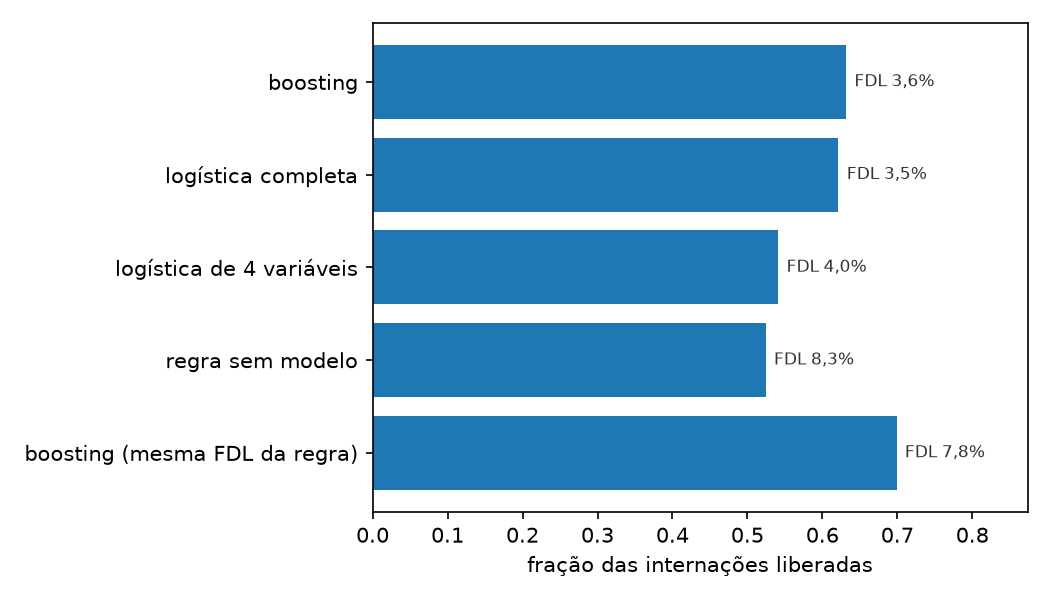

In [4]:
Image(filename=FIGURAS / "utilidade_x6.png")

## Calibração no teste de 2025

In [5]:
m = alfas["0,05"]["metricas_hgb"]
boot = alfas["0,05"]["bootstrap_hgb"]
tres = partial(num, casas=3)
pd.DataFrame(
    {
        "AUROC": (tres(m["auroc"]), intervalo(m["auroc_ic"], tres), intervalo(boot["auroc"]["hospitais"], tres)),
        "O/E": (tres(m["oe"]), intervalo(m["oe_ic"], tres), intervalo(boot["oe"]["hospitais"], tres)),
        "intercepto": (tres(m["intercepto"]), intervalo(m["intercepto_ic"], tres), "-"),
        "slope": (tres(m["slope"]), intervalo(m["slope_ic"], tres), "-"),
        "ICI": (num(m["ici"], 4), "-", "-"),
    },
    index=["valor", "IC de 95%", "IC, bootstrap de hospitais"],
).T

,valor,IC de 95%,"IC, bootstrap de hospitais"
AUROC,"0,898","0,893 a 0,903","0,879 a 0,916"
O/E,"0,939","0,914 a 0,963","0,886 a 0,998"
intercepto,"-0,078","-0,106 a -0,049",-
slope,"0,994","0,970 a 1,019",-
ICI,"0,0030",-,-


A AUROC foi de 0,898. Com O/E de 0,939 e intercepto de -0,078, o modelo previu mais óbitos do que houve em 2025, o mesmo
desvio que o X2 mostrou com a mortalidade em queda; o slope, de 0,994, fica perto de 1. Pelo bootstrap de hospitais, o
IC do O/E vai de 0,886 a 0,998.

Na figura, o eixo vai só até 0,2, e os histogramas de baixo, em escala logarítmica, mostram onde caem as probabilidades
previstas de sobreviventes e de óbitos.

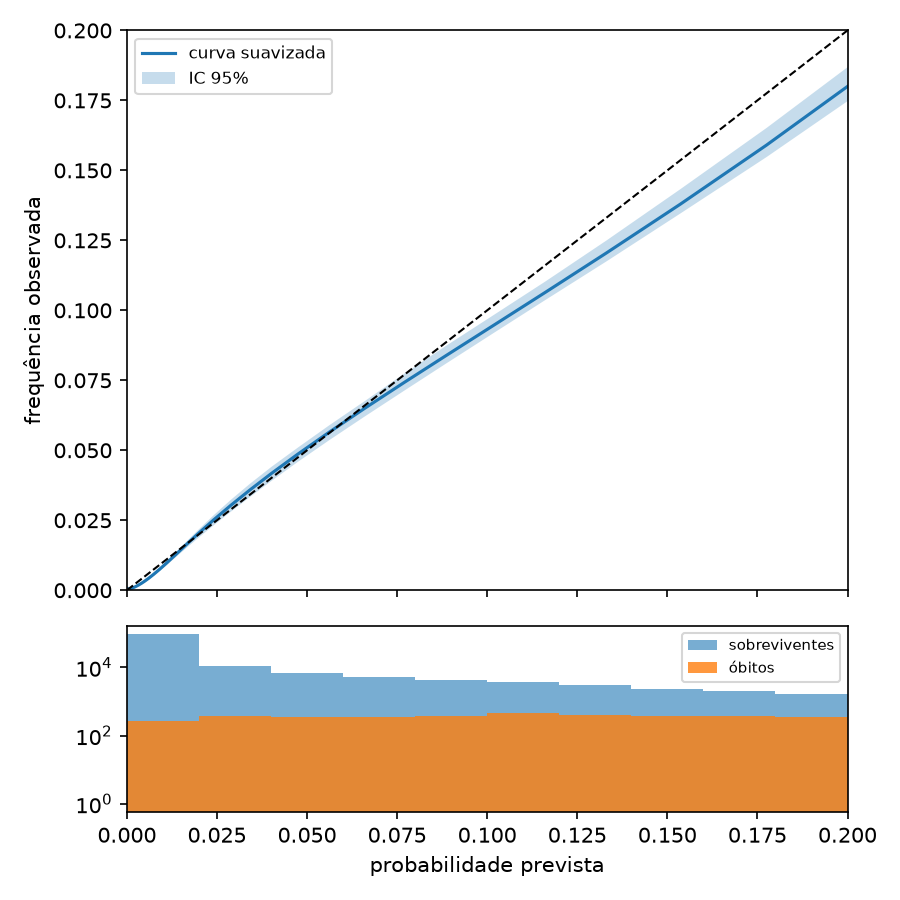

In [6]:
Image(filename=FIGURAS / "calibracao_x6.png")

## Importância por permutação

A importância é a queda da AUROC no teste quando as colunas de um bloco são embaralhadas juntas. O bloco cid junta o
capítulo e o CID de 3 caracteres; local, os municípios de residência e de atendimento, o hospital e o indicador de mesmo
município; tempo, o mês e o dia da semana da internação.

In [7]:
def quatro(v):
    return num(round(v, 4) + 0, 4)  # o + 0 evita "-0,0000"


def importancia(registros):
    t = pd.DataFrame(registros).set_index("bloco")
    return pd.DataFrame(
        {
            "queda da AUROC": t["queda_auroc"].map(quatro),
            "IC": [f"{quatro(lo)} a {quatro(hi)}" for lo, hi in zip(t["ic_lo"], t["ic_hi"])],
        }
    )


importancia(x6["importancia_blocos"])

,queda da AUROC,IC
bloco,,
cid,"0,1941","0,1883 a 0,2012"
idade,"0,0551","0,0509 a 0,0601"
local,"0,0280","0,0259 a 0,0303"
carater,"0,0244","0,0220 a 0,0277"
procedimento,"0,0193","0,0166 a 0,0217"
especialidade,"0,0030","0,0024 a 0,0033"
tempo,"0,0004","-0,0003 a 0,0012"
sexo,"0,0002","0,0001 a 0,0003"


O diagnóstico domina: embaralhar o bloco cid derruba a AUROC em 0,1941, mais de três vezes o efeito da idade, 0,0551.
Depois vêm local, caráter e procedimento, entre 0,0193 e 0,0280. Mês e dia da semana quase não contam, e o IC do bloco
tempo inclui zero.

In [8]:
importancia(x6["importancia_variaveis"]).rename_axis("variável")

,queda da AUROC,IC
variável,,
cid3,"0,1793","0,1704 a 0,1900"
idade_anos,"0,0551","0,0509 a 0,0601"
cnes,"0,0230","0,0204 a 0,0251"
proc_subgrupo,"0,0205","0,0170 a 0,0239"
carater,"0,0154","0,0140 a 0,0181"
cid_capitulo,"0,0060","0,0045 a 0,0077"
munic_res,"0,0034","0,0026 a 0,0041"
especialidade,"0,0028","0,0019 a 0,0041"
urgencia,"0,0021","0,0012 a 0,0031"


Sozinho, o CID de 3 caracteres responde por 0,1793 da queda, e o hospital (cnes), terceiro da lista, por 0,0230. São as
colunas que a S2 e a S6 tiram do modelo.

## Banda de custo

Uma alternativa à regra conformal é mandar para revisão as internações entre dois limiares escolhidos pelo menor
custo esperado. O X6 faz essa escolha na parte B da calibração, só para comparar o limiar de baixo com o do conformal.

In [9]:
# os mesmos custos de triagem_baixo_risco/experimentos/exploratorios.py
custos = {"c_fn": 10, "c_fp": 1, "c_defer": 0.3}
nomes = {"c_fn": "falso negativo", "c_fp": "falso positivo", "c_defer": "encaminhamento"}
print("custos:", "; ".join(f"{nomes[c]} {v:g}".replace(".", ",") for c, v in custos.items()))
pd.DataFrame(
    {
        f"α = {a}": {
            "início da banda de custo": num(res["banda_custo"]["t_lo"], 4),
            "limiar do conformal": num(res["banda_custo"]["limiar_conformal"], 4),
        }
        for a, res in alfas.items()
    }
)

custos: falso negativo 10; falso positivo 1; encaminhamento 0,3


,"α = 0,05","α = 0,10"
início da banda de custo,"0,0200","0,0200"
limiar do conformal,"0,0164","0,0316"


A banda de menor custo começa em 0,02, e abaixo disso a internação seria dispensada de revisão. O conformal de α = 0,05
libera abaixo de 0,0164, um corte mais baixo, e o de α = 0,10, abaixo de 0,0316. A banda sai do menor custo médio e não
diz quantos óbitos ficam abaixo do limiar; o conformal escolhe o limiar justamente por essa fração.